# Complete pMHC feature localization and image moments

Actively reconstruct all ten original128×128uint16 author frames using local Crocker–Grier mathematics. Original sdt-python measurements were independently executed and frozen before extraction. Source commitc9d1c09641e7d781a39a36e6fc89e429bf191ca9; source BSD-3-Clause, author movie CC0-1.0 by Lukas Schrangl. The authoritative archive/hashes are in test/validation.md.

The biological sample is identified by the author's pMHC_AF647 filename. No physical pixel spacing, exposure, photon gain or calibrated PSF is supplied. All positions are camera pixels and all intensities are ADU. The output is an effective image-feature estimator, not independent biological ground truth, photon counting, nanometer resolution or molecular stoichiometry.

## Physics and explicit local estimator

Fluorescence image $I_t(u,v)=b_t(u,v)+\sum_k m_{tk}h_{tk}(u-x_{tk},v-y_{tk})+\eta_t(u,v)$ combines smooth background $b$, optical spot profile $h$, subpixel centers $(x,y)$, feature intensity $m$, and noise $\eta$. Pixel centers are integers, x rightward and y downward. Camera gain and noise statistics are unknown.

Bandpass uses radius $r=3$, correlation length $\lambda=1$, Gaussian $g_i=\exp[-(i/2\lambda)^2]$ for $i=-3,\ldots,3$, and kernel $K_{ij}=[g_i g_j/B-1/49]/K_0$, where $B=(\sum_i g_i)^2$ and $K_0=(\sum_i g_i^2)^2/B-B/49$. Valid FFT convolution is embedded into a zero-border image and clipped at zero. Circular dilation finds maxima above300ADU, and initial circular aperture mass must exceed5000ADU.

The circular aperture mask is $W=1[i^2+j^2\le3.5^2]$. First centroid is the intensity-weighted coordinate average, followed by bilinear recentering and a second moment pass. Refined mass is $M=\sum JW$; radius is $R=\sqrt{\sum J[(i^2+j^2)W+1/6]/M}$. Eccentricity is $e=\sqrt{(\sum JC)^2+(\sum JS)^2}/(M-J_{00}+10^{-6})$, with $C=W\cos2\theta$, $S=W\sin2\theta$, and their central values set0. The angle $\theta=\operatorname{atan2}(i,j)$ follows image coordinates. All five inferred moment quantities are retained alongside frame index. Exactly two centroid passes, no optimization stopping rule, are used.

Finite apertures and filtering change integrated intensity. This estimator's mass/size are not the uniquely recoverable raw-source flux/PSF width. Independent analytic Gaussian and integer-translation checks complement exact upstream parity.

In [1]:
from pathlib import Path
import sys,time,json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd().resolve()
if ROOT.name=='notebooks':ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.main import run
from src.preprocessing import load_observations
from src.visualization import experiments,figures,table_metrics
frames=load_observations(ROOT/'data/raw_data.npz')
start=time.perf_counter()
fresh,seconds=run(ROOT/'data/raw_data.npz',ROOT/'output/reconstruction.npz')
with np.load(ROOT/'evaluation/baseline_reference.npz',allow_pickle=False) as z:original=z['reconstruction']
results=experiments(frames,original)
assert np.array_equal(fresh,results['fresh'])
results['measurements']['canonical_runtime_seconds']=seconds
results['measurements']['full_experiments_runtime_seconds']=time.perf_counter()-start
print(json.dumps(results['measurements'],indent=2))
(ROOT/'notebooks/reference_outputs/fresh_measurements.json').write_text(json.dumps(results['measurements'],indent=2,allow_nan=False),encoding='utf-8')
plots=figures(frames,results)
plt.close('all')

{
  "canonical_count": 77,
  "counts_by_frame": [
    14,
    21,
    12,
    7,
    6,
    5,
    6,
    2,
    2,
    2
  ],
  "upstream_comparison": {
    "detection_f1": 1.0,
    "position_rmse_pixels": 0.0,
    "mass_relative_rmse": 0.0,
    "size_rmse_pixels": 0.0,
    "ecc_rmse": 0.0
  },
  "max_absolute_upstream_difference": 0.0,
  "integer_comparison": {
    "detection_f1": 0.7532467532467533,
    "position_rmse_pixels": 0.5859488483642323,
    "mass_relative_rmse": 0.496742636335202,
    "size_rmse_pixels": 0.496742636335202,
    "ecc_rmse": 0.496742636335202
  },
  "no_bandpass_comparison": {
    "detection_f1": 0.06297229219143577,
    "position_rmse_pixels": 0.2655049260307854,
    "mass_relative_rmse": 1.3463859347466323,
    "size_rmse_pixels": 0.542847299553941,
    "ecc_rmse": 0.1666441215161902
  },
  "no_bandpass_count": 2305,
  "threshold_counts": [
    77,
    77,
    77,
    65
  ],
  "radius_counts": [
    58,
    77,
    88,
    96
  ],
  "noise_counts": [
    7

## All complete native observations and retained localizations

Every author frame is shown at the same full-data intensity display range, without percentile clipping or denoising. Original positions are orange squares and newly computed positions cyan crosses. Coincidence documents numerical parity; it does not establish physical localization accuracy. Coordinates refer to original integer pixel centers.

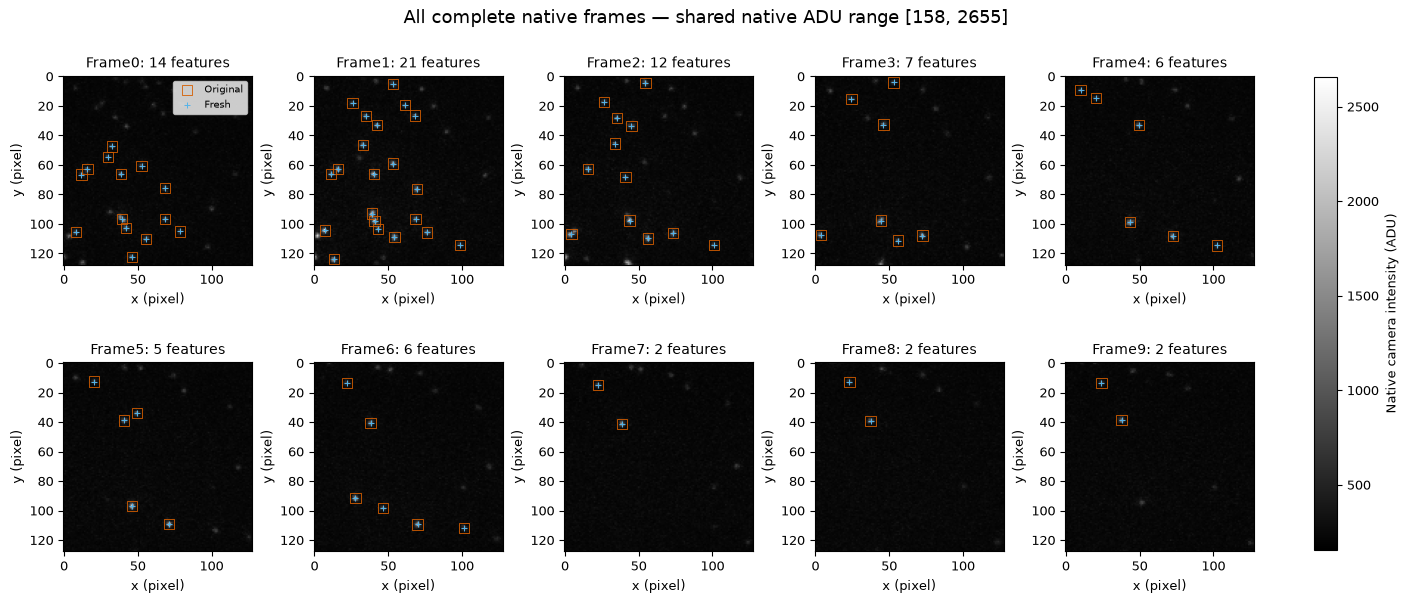

In [2]:
display(plots['native_movie_localizations']);plt.close(plots['native_movie_localizations'])

## Subpixel centers, complete moment distributions and parity

The first two panels are explicitly labeled display zooms selected around an observed frame0 feature. The task observations themselves remain uncropped. Blue/white pixel and orange subpixel marks illustrate the moment correction. The full-frame count series and distributions use every retained feature across all ten frames. The original/fresh position comparison checks an independently executed implementation, not the output of the same cleaned function used as its own oracle.

Integer-rounded centers are also computed as a simple baseline; their measured position RMS against the subpixel estimator is printed above. No artificial zero-valued method fills a missing comparison.

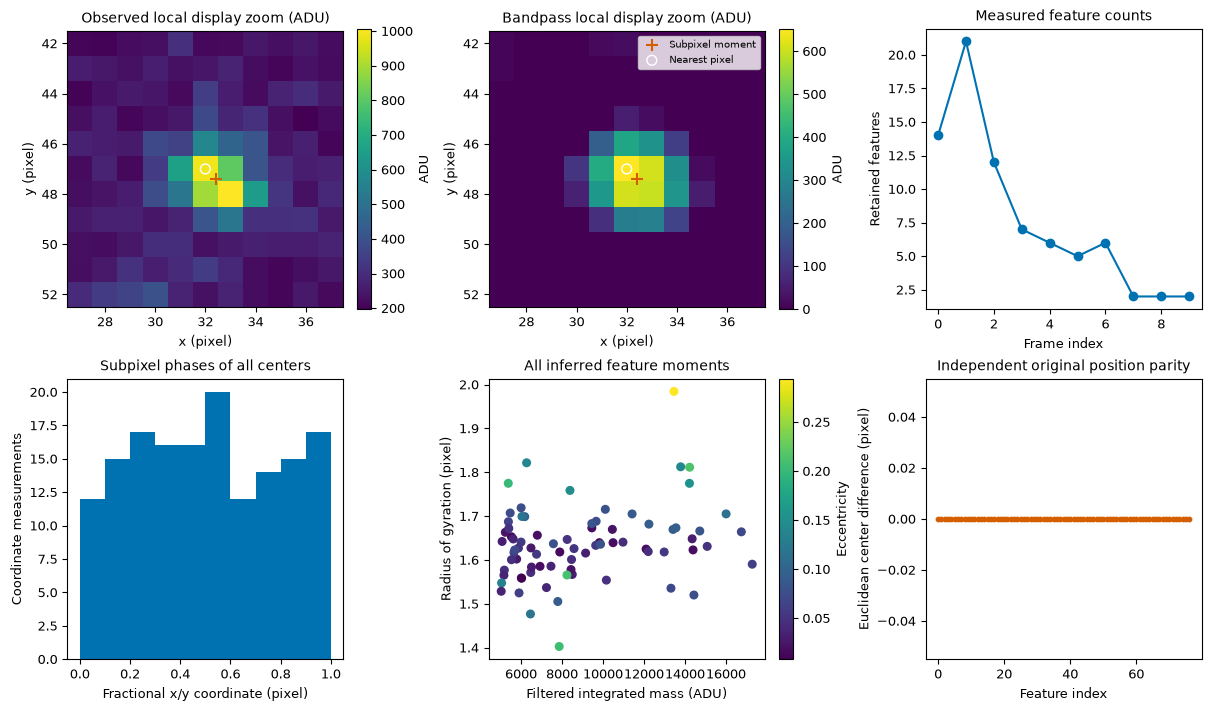

In [3]:
display(plots['subpixel_moments_parity']);plt.close(plots['subpixel_moments_parity'])

## Full-movie threshold, support and noise sensitivity

Every point below comes from a fresh run on all ten frames. Signal thresholds150,300,450,600ADU and feature radii2,3,4,5pixels probe detection/moment conventions. Controlled additive Gaussian stress levels0,25,50,100ADU are explicitly synthetic perturbations of the measured movie, with experiment seed20261020. This is a reproducible stress experiment, not a calibrated camera noise model and not new benchmark data. No negative-stress values are clamped before preprocessing.

All variants are compared with the canonical moment estimator using same-frame assignment within0.5pixel. F1 measures estimator agreement, not biological accuracy. The no-bandpass ablation and integer baseline are computed and numerically reported above; their changes expose the role of background suppression and subpixel refinement.

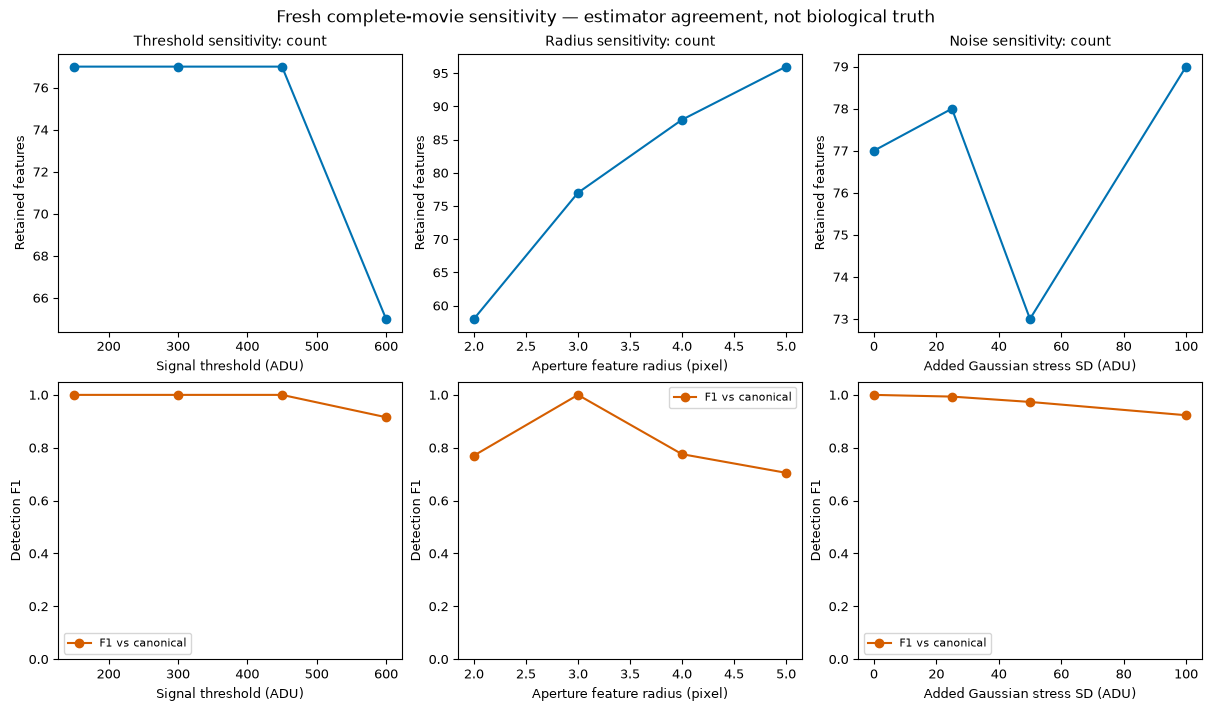

In [4]:
display(plots['threshold_support_noise']);plt.close(plots['threshold_support_noise'])

In [5]:
from src.physics_model import gaussian_image
from src.solvers import locate
# Independent known analytic object; does not replace measured benchmark frames.
analytic=gaussian_image((64,64),np.array([[25.3,30.6]]),[20000.],[1.])
analytic_result=locate(analytic,4,10,1000,bandpass=False)
np.testing.assert_allclose(analytic_result[0,:2],[25.3,30.6],atol=.01)
print('Independent known Gaussian center error (pixel):',analytic_result[0,:2]-[25.3,30.6])
import importlib.util
spec=importlib.util.spec_from_file_location('independent_judge',ROOT/'evaluation/judge.py')
judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report=judge.evaluate(ROOT/'output/reconstruction.npz');assert report['status']=='pass',report
print(json.dumps(report,indent=2))

Independent known Gaussian center error (pixel): [ 6.15067689e-05 -3.31891835e-05]
{
  "status": "pass",
  "passed": true,
  "metrics": {
    "detection_f1": 1.0,
    "position_rmse_pixels": 0.0,
    "mass_relative_rmse": 0.0,
    "size_rmse_pixels": 0.0,
    "ecc_rmse": 0.0
  },
  "thresholds": {
    "detection_f1": {
      "comparison": ">=",
      "boundary": 0.99
    },
    "position_rmse_pixels": {
      "comparison": "<=",
      "boundary": 1e-08
    },
    "mass_relative_rmse": {
      "comparison": "<=",
      "boundary": 1e-08
    },
    "size_rmse_pixels": {
      "comparison": "<=",
      "boundary": 1e-08
    },
    "ecc_rmse": {
      "comparison": "<=",
      "boundary": 1e-08
    }
  },
  "errors": []
}


## Conclusion and limits

The complete native movie is actively localized and all effective moment outputs reproduce the independently executed upstream method. Analytic symmetry/flux/translation checks support pixel-coordinate and moment consistency. The method depends on aperture/background/threshold conventions and cannot separate unresolved overlaps or prove that every true molecule was detected. With no calibrated gain, exposure, physical pixel spacing or independent truth, no photon count, diffusion coefficient, molecular stoichiometry or nanometer-resolution claim follows from these tables.